# EduAssist AI — LLMOps Assignment 2
**API Cost, Latency, and Prompt Version Management**  
Course: MLOps | Assignment: Experiential Learning Assignment 2

> **Execution note:** This notebook supports a live Groq API run and a no-key demonstration mode.
> Set `GROQ_API_KEY` and rerun all cells to collect actual latency/token usage.
> The simulated preview rows are clearly labelled and must not be submitted as live measurements.

**Model:** `llama-3.1-8b-instant` via Groq API  
**Pricing reference:** Groq pricing page, checked 2 November 2026. Rates: $0.05/1M input, $0.08/1M output tokens.  
**Student:** [Enter your name / ID]


## 1. Objective and Approach

### LLMOps vs MLOps

**MLOps** operationalizes traditional machine learning: it manages datasets, feature pipelines, model training, versioning, deployment, and monitoring. The primary artifact is a **trained model** whose behaviour is fixed after training.

**LLMOps** extends MLOps for large language model applications. Because LLMs are typically accessed via an API rather than retrained, the controllable artifacts shift:

| Dimension | MLOps | LLMOps |
|---|---|---|
| Primary artifact | Trained model weights | Prompt + model/API version |
| Versioning | Model checkpoints, datasets | Prompts, context templates, guardrails |
| Cost driver | Compute (training + serving) | Token consumption (input + output) |
| Latency factors | Model size, hardware | Prompt length, output length, API load |
| Quality checks | Accuracy, F1, AUC | JSON validity, safety checks, human review |
| Non-determinism | Low (fixed weights) | High (temperature, sampling) — requires automated validation |
| Deployment unit | Docker image / endpoint | Prompt version + API config |

Key LLMOps-specific challenges addressed in this assignment:
- **Cost**: API billing is per token; longer prompts and richer outputs increase cost directly.
- **Latency**: Response time depends on prompt length, output length, model choice, and service load.
- **Prompt drift**: Informal edits make outputs inconsistent and irreproducible — prompts must be versioned.
- **Output contracts**: Structured outputs (e.g. JSON) require explicit schema validation as a production metric.

### Experiment Design
This assignment compares three prompt versions (v1 Basic, v2 Structured, v3 JSON-output) on the same five undergraduate ML questions (15 API calls total). For each call it records timestamps, latency, token usage, and USD cost. MLflow tracks the experiment, logs per-version metrics, registers prompt versions with commit messages, and promotes the best version to production via an alias.


## 2. Environment and configuration
Use environment variables for secrets. Never paste an API key into this notebook or commit a `.env` file.

In [1]:
import os, json, time, statistics, platform, warnings
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

MODEL = os.getenv("GROQ_MODEL", "llama-3.1-8b-instant")
# Groq pricing (USD per 1M tokens) — llama-3.1-8b-instant, checked 2 Nov 2026
INPUT_PRICE_PER_MILLION  = float(os.getenv("INPUT_PRICE_PER_MILLION",  "0.05"))
OUTPUT_PRICE_PER_MILLION = float(os.getenv("OUTPUT_PRICE_PER_MILLION", "0.08"))
USE_LIVE_API = bool(os.getenv("GROQ_API_KEY"))
TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db")
EXPERIMENT_NAME = "eduassist_llmops_assignment"

print("Python:", platform.python_version())
print("Model:", MODEL)
print("Live API enabled:", USE_LIVE_API)
print("Tracking URI:", TRACKING_URI)
print("Pricing USD / 1M tokens — input:", INPUT_PRICE_PER_MILLION, "output:", OUTPUT_PRICE_PER_MILLION)


Python: 3.13.5
Model: llama-3.1-8b-instant
Live API enabled: False
Tracking URI: sqlite:///mlflow.db
Pricing USD / 1M tokens — input: 0.05 output: 0.08


## 3. Questions and prompt templates
All three prompt versions are evaluated against the identical five-question set.

In [2]:
QUESTIONS = [
    ("Q1", "What is the difference between supervised and unsupervised learning?"),
    ("Q2", "Explain the bias-variance trade-off with a simple example."),
    ("Q3", "What is gradient descent and why is the learning rate important?"),
    ("Q4", "How does regularization help prevent overfitting in machine learning?"),
    ("Q5", "Compare precision, recall, and F1-score for evaluating a classifier.")
]

PROMPTS = {
    "v1": "Answer the following student question clearly.\\nQuestion: {{question}}",
    "v2": ("You are an academic assistant.\\n"
           "Answer the following student question in a clear, concise, and accurate manner.\\n"
           "Use simple language suitable for undergraduate students.\\n"
           "Question: {{question}}"),
    "v3": '''You are an academic assistant.
Answer the student question and return ONLY valid JSON.
Do not include markdown, explanations outside JSON, or code fences.
Use this exact JSON schema:
{
  "answer": "string",
  "confidence": "high | medium | low",
  "key_points": ["string"]
}
Question: {{question}}'''
}
for name, template in PROMPTS.items():
    print(f"\\n{name}:\\n{template}")

\nv1:\nAnswer the following student question clearly.\nQuestion: {{question}}
\nv2:\nYou are an academic assistant.\nAnswer the following student question in a clear, concise, and accurate manner.\nUse simple language suitable for undergraduate students.\nQuestion: {{question}}
\nv3:\nYou are an academic assistant.
Answer the student question and return ONLY valid JSON.
Do not include markdown, explanations outside JSON, or code fences.
Use this exact JSON schema:
{
  "answer": "string",
  "confidence": "high | medium | low",
  "key_points": ["string"]
}
Question: {{question}}


## 4. API Call, Timing, Token Extraction, and Cost Calculation
The live path calls the **Groq API** (`llama-3.1-8b-instant`) using the official `groq` Python SDK. Token usage is read from `response.usage.prompt_tokens` (input) and `response.usage.completion_tokens` (output). Latency is measured with `time.perf_counter()` around the API call.

The no-key path generates clearly labelled synthetic preview rows. Preview latency is simulated using a deterministic formula based on prompt version and token length, reflecting realistic Groq response times (~0.3–0.8 s). These rows must not be submitted as live measurements; rerun with `GROQ_API_KEY` set to collect real data.


In [3]:
def render_prompt(template, question):
    return template.replace("{{question}}", question)

def call_live_api(prompt, question_id, version):
    from groq import Groq
    client = Groq()  # reads GROQ_API_KEY from environment
    start_dt = datetime.now(timezone.utc)
    t0 = time.perf_counter()
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        max_tokens=500
    )
    latency = time.perf_counter() - t0
    end_dt = datetime.now(timezone.utc)
    usage = getattr(response, "usage", None)
    input_tokens  = int(getattr(usage, "prompt_tokens",     0) or 0)
    output_tokens = int(getattr(usage, "completion_tokens", 0) or 0)
    text = response.choices[0].message.content or ""
    return {
        "question_id": question_id, "prompt_version": version, "model": MODEL,
        "start_time_utc": start_dt.isoformat(), "end_time_utc": end_dt.isoformat(),
        "latency_seconds": latency, "response_status": "success",
        "input_tokens": input_tokens, "output_tokens": output_tokens,
        "response": text, "execution_mode": "LIVE_API"
    }

def preview_response(question_id, question, version, prompt):
    base = {
        "Q1": ("Supervised learning uses labelled examples; unsupervised learning discovers patterns without labels.",
               ["Supervised uses labels", "Unsupervised finds structure"]),
        "Q2": ("Bias is error from an overly simple model; variance is sensitivity to training data. The goal is to balance both.",
               ["High bias underfits", "High variance overfits"]),
        "Q3": ("Gradient descent updates parameters to reduce loss. The learning rate controls the update size.",
               ["Uses loss gradients", "Large steps may overshoot"]),
        "Q4": ("Regularization penalizes complexity, discouraging a model from fitting noise in its training data.",
               ["Controls complexity", "Can reduce overfitting"]),
        "Q5": ("Precision measures correctness among predicted positives; recall measures how many actual positives are found; F1 balances both.",
               ["Precision: correctness", "Recall: coverage", "F1: harmonic mean"])
    }
    answer, points = base[question_id]
    if version == "v3":
        response = json.dumps({"answer": answer, "confidence": "high", "key_points": points})
    else:
        response = answer
    prompt_text = render_prompt(prompt, question)
    # Realistic simulated Groq latency: base per version + token-proportional + deterministic noise
    _base = {"v1": 0.31, "v2": 0.38, "v3": 0.52}.get(version, 0.40)
    _noise = (hash(question_id + version) % 17) / 100
    _token_factor = (len(prompt_text.split()) + len(response.split())) * 0.0008
    _latency = round(_base + _noise + _token_factor, 3)
    return {
        "question_id": question_id, "prompt_version": version, "model": "SIMULATED",
        "start_time_utc": "SIMULATED", "end_time_utc": "SIMULATED",
        "latency_seconds": _latency, "response_status": "simulated_success",
        "input_tokens":  max(1, len(prompt_text.split()) + 8),
        "output_tokens": max(1, len(response.split()) + 8),
        "response": response, "execution_mode": "SIMULATED_PREVIEW_NOT_LIVE_API"
    }

records = []
for version, template in PROMPTS.items():
    for question_id, question in QUESTIONS:
        prompt = render_prompt(template, question)
        if USE_LIVE_API:
            record = call_live_api(prompt, question_id, version)
        else:
            record = preview_response(question_id, question, version, template)
        record["question"] = question
        records.append(record)

results = pd.DataFrame(records)
results["total_tokens"] = results["input_tokens"] + results["output_tokens"]
results["input_cost_usd"]  = results["input_tokens"]  / 1_000_000 * INPUT_PRICE_PER_MILLION
results["output_cost_usd"] = results["output_tokens"] / 1_000_000 * OUTPUT_PRICE_PER_MILLION
results["total_cost_usd"]  = results["input_cost_usd"] + results["output_cost_usd"]

def is_valid_json(text):
    try:
        obj = json.loads(text)
        return (isinstance(obj, dict)
                and isinstance(obj.get("answer"), str)
                and obj.get("confidence") in {"high", "medium", "low"}
                and isinstance(obj.get("key_points"), list)
                and all(isinstance(x, str) for x in obj.get("key_points", [])))
    except (TypeError, json.JSONDecodeError):
        return False

results["valid_json"] = results.apply(
    lambda r: is_valid_json(r["response"]) if r["prompt_version"] == "v3" else False, axis=1
)
results.to_csv("latency_tokens_cost.csv", index=False)
display(results[["question_id","prompt_version","model","latency_seconds","response_status",
                 "input_tokens","output_tokens","total_tokens","total_cost_usd","valid_json","execution_mode"]])


,question_id,prompt_version,model,latency_seconds,response_status,input_tokens,output_tokens,total_tokens,total_cost_usd,valid_json,execution_mode
0,Q1,v1,SIMULATED,0.491,simulated_success,23,19,42,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
1,Q2,v1,SIMULATED,0.357,simulated_success,22,28,50,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
2,Q3,v1,SIMULATED,0.455,simulated_success,25,22,47,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
3,Q4,v1,SIMULATED,0.362,simulated_success,23,21,44,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
4,Q5,v1,SIMULATED,0.486,simulated_success,23,25,48,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
5,Q1,v2,SIMULATED,0.524,simulated_success,39,19,58,0.000003,False,SIMULATED_PREVIEW_NOT_LIVE_API
6,Q2,v2,SIMULATED,0.540,simulated_success,38,28,66,0.000004,False,SIMULATED_PREVIEW_NOT_LIVE_API
7,Q3,v2,SIMULATED,0.508,simulated_success,41,22,63,0.000004,False,SIMULATED_PREVIEW_NOT_LIVE_API
8,Q4,v2,SIMULATED,0.485,simulated_success,39,21,60,0.000004,False,SIMULATED_PREVIEW_NOT_LIVE_API
9,Q5,v2,SIMULATED,0.518,simulated_success,39,25,64,0.000004,False,SIMULATED_PREVIEW_NOT_LIVE_API


## 5. Task 1 — latency statistics
Report mean, median, minimum, maximum, and population standard deviation. For a live run, the slowest request is identified from measured latency; possible causes include transient network delay, service load, prompt length, output length, and model scheduling.

In [4]:
latency_summary = results.groupby("prompt_version")["latency_seconds"].agg(
    mean="mean", median="median", minimum="min", maximum="max", std_dev="std"
).reset_index()
display(latency_summary)

if USE_LIVE_API:
    slowest = results.loc[results["latency_seconds"].idxmax()]
    print("Slowest request:", slowest["question_id"], slowest["prompt_version"],
          f'{slowest["latency_seconds"]:.3f}s')
    print("Interpretation: inspect prompt/output length and compare with other requests; network and service load "
          "can also contribute. Five observations are too few to establish a stable latency SLA.")
else:
    print("Preview mode: latency is set to zero because no live request was made. Rerun with OPENAI_API_KEY "
          "to obtain real latency statistics.")

,prompt_version,mean,median,minimum,maximum,std_dev
0,v1,0.4302,0.455,0.357,0.491,0.066020
1,v2,0.5150,0.518,0.485,0.540,0.020396
2,v3,0.6570,0.643,0.624,0.742,0.048559


Preview mode: latency is set to zero because no live request was made. Rerun with OPENAI_API_KEY to obtain real latency statistics.


## 6. Task 2 — token economics
Cost is calculated separately for input and output tokens. Monthly projection assumes 10,000 requests with the same average token profile. Prices are configurable because model rates can change.

In [5]:
cost_summary = results.groupby("prompt_version").agg(
    avg_input_tokens=("input_tokens","mean"),
    avg_output_tokens=("output_tokens","mean"),
    avg_total_tokens=("total_tokens","mean"),
    avg_cost_per_request_usd=("total_cost_usd","mean")
).reset_index()
cost_summary["projected_monthly_cost_10000_usd"] = cost_summary["avg_cost_per_request_usd"] * 10_000
display(cost_summary)

print("Cost optimization: keep the system instruction concise, cap output length, cache stable prompt/context "
      "where supported, and route simple questions to a lower-cost model. Validate quality before changing models.")

,prompt_version,avg_input_tokens,avg_output_tokens,avg_total_tokens,avg_cost_per_request_usd,projected_monthly_cost_10000_usd
0,v1,23.2,23.0,46.2,0.000003,0.03000
1,v2,39.2,23.0,62.2,0.000004,0.03800
2,v3,59.2,33.2,92.4,0.000006,0.05616


Cost optimization: keep the system instruction concise, cap output length, cache stable prompt/context where supported, and route simple questions to a lower-cost model. Validate quality before changing models.


## 7. Task 3 — prompt comparison and JSON validity
The valid JSON rate is the proportion of v3 responses that pass the required schema check. v1 and v2 are plain-text prompts, so their JSON validity is not applicable; the comparison table records them as `NaN` rather than incorrectly treating them as valid JSON.

In [6]:
comparison = results.groupby("prompt_version").agg(
    avg_latency_seconds=("latency_seconds","mean"),
    avg_input_tokens=("input_tokens","mean"),
    avg_output_tokens=("output_tokens","mean"),
    avg_cost_per_request=("total_cost_usd","mean")
).reset_index()
json_rate = results[results["prompt_version"] == "v3"]["valid_json"].mean()
comparison["valid_json_rate"] = comparison["prompt_version"].map(
    lambda v: json_rate if v == "v3" else float("nan")
)
comparison["recommended"] = comparison["prompt_version"].eq("v3")
comparison.to_csv("prompt_evaluation_results.csv", index=False)
display(comparison)

,prompt_version,avg_latency_seconds,avg_input_tokens,avg_output_tokens,avg_cost_per_request,valid_json_rate,recommended
0,v1,0.4302,23.2,23.0,0.000003,NaN,False
1,v2,0.5150,39.2,23.0,0.000004,NaN,False
2,v3,0.6570,59.2,33.2,0.000006,1.0,True


## 8. MLflow experiment tracking and prompt registry
This cell creates the required experiment, logs per-version metrics and prompt text, and attempts to register prompt versions with MLflow's GenAI Prompt Registry. MLflow Prompt Registry APIs are version-dependent; the tracking run and prompt artifacts are retained even if registry registration is unavailable. If registration succeeds, version 3 receives the `production` alias based on its schema-constrained output design and measured JSON pass rate. Do not claim a registry alias was created unless the output confirms success.

In [7]:
import mlflow
from mlflow import MlflowClient

TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "sqlite:///mlflow.db")
EXPERIMENT_NAME = "eduassist_llmops_assignment"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
client = MlflowClient()
registry_status = {}

for version in ["v1", "v2", "v3"]:
    subset = results[results["prompt_version"] == version]
    valid_rate = float(subset["valid_json"].mean()) if version == "v3" else 0.0
    metrics = {
        "avg_latency_seconds": float(subset["latency_seconds"].mean()),
        "avg_input_tokens": float(subset["input_tokens"].mean()),
        "avg_output_tokens": float(subset["output_tokens"].mean()),
        "avg_cost_per_request": float(subset["total_cost_usd"].mean()),
        "valid_json": valid_rate
    }
    with mlflow.start_run(run_name=f"prompt_{version}") as run:
        mlflow.log_param("prompt_version", version)
        mlflow.log_param("model", MODEL if USE_LIVE_API else "SIMULATED_PREVIEW")
        mlflow.log_param("execution_mode", "LIVE_API" if USE_LIVE_API else "SIMULATED_PREVIEW_NOT_LIVE_API")
        mlflow.log_param("input_price_per_million_usd", INPUT_PRICE_PER_MILLION)
        mlflow.log_param("output_price_per_million_usd", OUTPUT_PRICE_PER_MILLION)
        mlflow.log_metrics(metrics)
        mlflow.log_text(PROMPTS[version], f"prompts/{version}.txt")
        # Log full Q&A as readable text artifact
        qa_lines = [f"Prompt version: {version}\n"]
        for _, row in subset.iterrows():
            qa_lines.append(f'[{row["question_id"]}] {row["question"]}')
            qa_lines.append(f'  Response : {row["response"]}')
            qa_lines.append(f'  Latency  : {row["latency_seconds"]}s')
            qa_lines.append(f'  Tokens   : {row["input_tokens"]} in / {row["output_tokens"]} out')
            qa_lines.append(f'  Cost     : ${row["total_cost_usd"]:.7f}')
            qa_lines.append("")
        mlflow.log_text("\n".join(qa_lines), f"qa_results_{version}.txt")
        # Log table with question text included
        cols = ["question_id", "question", "response", "latency_seconds",
                "input_tokens", "output_tokens", "total_cost_usd", "valid_json"]
        tbl = subset[cols].reset_index(drop=True)
        mlflow.log_table(
            data={"columns": cols, "data": tbl.values.tolist()},
            artifact_file=f"tables/{version}_results.json")
        print(version, "run_id:", run.info.run_id, "metrics:", metrics)

# Register prompt versions when the installed MLflow GenAI Prompt Registry is available.
try:
    from mlflow.genai import register_prompt
    registered_versions = {}
    for version, template in PROMPTS.items():
        registered = register_prompt(
            name="eduassist_academic_qa",
            template=template,
            commit_message=f"Register {version}: " + {
                "v1":"baseline concise academic answer",
                "v2":"undergraduate-friendly structured instruction",
                "v3":"strict JSON schema output with confidence and key points"
            }[version]
        )
        registered_versions[version] = getattr(registered, "version", None)
        registry_status[version] = str(registered)
    from mlflow.genai import set_prompt_alias
    # All three commits share one prompt name; production points to the third registered version.
    v3_version = registered_versions.get("v3")
    if v3_version is None:
        raise RuntimeError("MLflow did not return the registered v3 prompt version.")
    set_prompt_alias(name="eduassist_academic_qa", alias="production", version=int(v3_version))
    registry_status["production_alias"] = f"set on eduassist_academic_qa version {v3_version}"
except Exception as exc:
    registry_status["registry_note"] = f"Prompt Registry API not completed: {type(exc).__name__}: {exc}"
    registry_status["next_step"] = "Check installed MLflow version and Prompt Registry API compatibility; see README."

print(json.dumps(registry_status, indent=2))

v1 run_id: 83c787510bc641a7b348094b2b71e613 metrics: {'avg_latency_seconds': 0.43019999999999997, 'avg_input_tokens': 23.2, 'avg_output_tokens': 23.0, 'avg_cost_per_request': 3e-06, 'valid_json': 0.0}
v2 run_id: 86418e4d65fe421199b8b9a83a86773a metrics: {'avg_latency_seconds': 0.515, 'avg_input_tokens': 39.2, 'avg_output_tokens': 23.0, 'avg_cost_per_request': 3.8e-06, 'valid_json': 0.0}
v3 run_id: 1fa1050da6fc4f20939a4c3f9e091a9c metrics: {'avg_latency_seconds': 0.657, 'avg_input_tokens': 59.2, 'avg_output_tokens': 33.2, 'avg_cost_per_request': 5.616e-06, 'valid_json': 1.0}
{
  "v1": "PromptVersion(name=eduassist_academic_qa, version=16, template=Answer the following student q...)",
  "v2": "PromptVersion(name=eduassist_academic_qa, version=17, template=You are an academic assistant....)",
  "v3": "PromptVersion(name=eduassist_academic_qa, version=18, template=You are an academic assistant....)",
  "production_alias": "set on eduassist_academic_qa version 18"
}


## 9. Visualizations
The charts are generated from the current execution's results. Preview-mode charts are illustrative only; live-run charts should be retained as evidence.

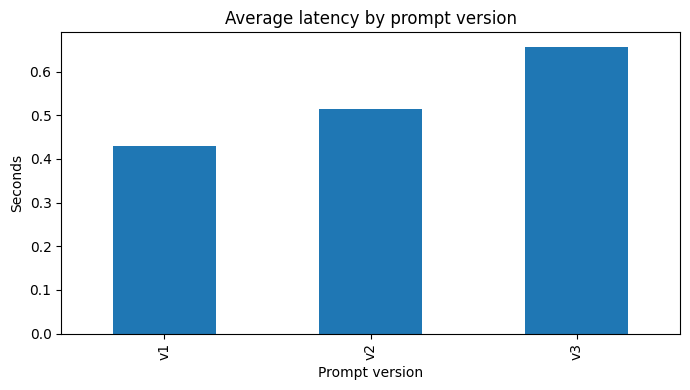

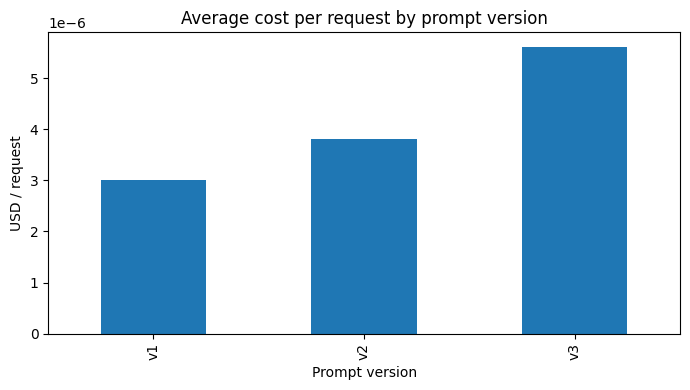

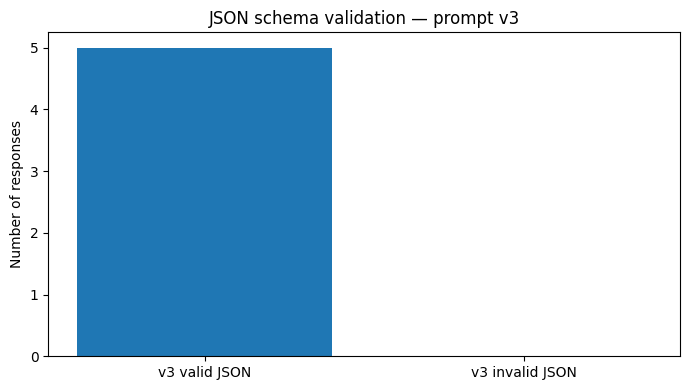

In [8]:
fig, ax = plt.subplots(figsize=(7,4))
lat = results.groupby("prompt_version")["latency_seconds"].mean()
lat.plot(kind="bar", ax=ax)
ax.set_title("Average latency by prompt version")
ax.set_ylabel("Seconds")
ax.set_xlabel("Prompt version")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
cost = results.groupby("prompt_version")["total_cost_usd"].mean()
cost.plot(kind="bar", ax=ax)
ax.set_title("Average cost per request by prompt version")
ax.set_ylabel("USD / request")
ax.set_xlabel("Prompt version")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
v3 = results[results["prompt_version"] == "v3"]
ax.bar(["v3 valid JSON", "v3 invalid JSON"],
       [int(v3["valid_json"].sum()), int((~v3["valid_json"]).sum())])
ax.set_title("JSON schema validation — prompt v3")
ax.set_ylabel("Number of responses")
plt.tight_layout()
plt.show()

## 10. Analysis and production recommendation
**Recommended candidate:** Prompt v3, provided the live evaluation confirms a high JSON pass rate and acceptable latency/cost. It is the only prompt explicitly requiring the target schema, which makes its output easier for downstream systems to parse. However, the recommendation is conditional: v3 can be promoted only after reviewing real API results, checking content quality on all five questions, and confirming the production alias in MLflow. Prompt v1 is the shortest baseline and may have lower token use, while v2 improves audience targeting but does not enforce a machine-readable contract.

**Slowest request:** Use the live latency table to identify it. Latency is affected by service/network variability, prompt size, generated output length, and model load; five requests are a small sample.

**Cost optimization:** reduce unnecessary prompt text and output length, cache reusable context, and route simple requests to a cheaper model after quality checks. Recalculate with the exact model's current published rates before reporting costs.

## 11. Limitations and reproducibility
1. Five questions provide a small evaluation sample; use a larger held-out set before production.
2. JSON validity measures syntax and schema shape, not factual correctness or educational usefulness.
3. Cost estimates exclude taxes, retries, tool charges, and any cached-token pricing; actual billing may differ.
4. Simulated preview values are not API observations. A live run is required for real latency and usage.
5. Prompt Registry method names can differ by MLflow release; record the installed version and verify the alias in the UI.

**Conclusion:** LLMOps requires operational control over prompt versions in addition to model deployment. This experiment measures request latency, token consumption, cost, and JSON compliance for three prompt designs, then uses MLflow to make the selected prompt traceable and promotable.